In [1]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import LabelEncoder 
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV


import shap


In [51]:
# os.chdir("/home/kaderi/Feroj/4th paper/data_collection/papilary")
data = pd.read_csv("/home/kaderi/Feroj/T2DM_AND_OVARIAN/T2DM/T2DM_corrected_datasets_five_updated.csv",index_col= 0)
degs = pd.read_csv("/home/kaderi/Feroj/T2DM&TNBC/common_TNBC_limma_updated.csv")

In [52]:
control = data[data.columns[data.columns.str.startswith("Con")]]
disease = data[data.columns[data.columns.str.startswith("Dis")]]
row_names = data.index
col_names = data.columns
print(row_names)
samples = []
for i in col_names:
    if "Dis" in i:
        samples.append('Disease')
    else:
        samples.append("Control")
samples

Index(['PRPF8', 'CAPNS1', 'RPL35', 'EIF3D', 'PARK7', 'SRP14', 'RPL11',
       'RPS27A', 'FAU', 'CFL1',
       ...
       'AP1M2', 'TMEM80', 'GPR124', 'MAN1B1', 'HNRNPUL2', 'RABEP2', 'CX3CL1',
       'ACSM5', 'LRTM1', 'MEX3D'],
      dtype='object', name='genes', length=10998)


['Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Control',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Disease',
 'Di

In [53]:
X= data.select_dtypes(include='float').transpose()
X1 = X[degs['x'].tolist()]

In [ ]:
encoder= LabelEncoder()

scaler = StandardScaler() ##scaling count hoy na
Y = encoder.fit_transform(samples)
X2 = scaler.fit_transform(X1)

<Axes: >

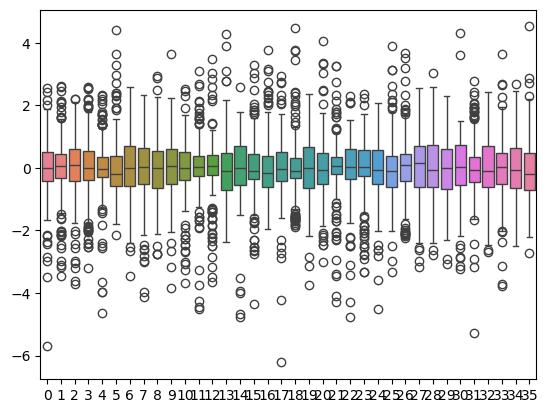

In [23]:
sns.boxplot(X2)

In [55]:
column_transformer = make_column_transformer(
    (StandardScaler(), X1.columns),
    remainder='passthrough'
)
pipe = Pipeline(steps=[
    ('model', XGBClassifier(eval_metric='logloss'))
])

param_grid = {
    'model__n_estimators': [50, 100, 150],
    'model__max_depth': [3, 5, 7],
    'model__learning_rate': [0.01, 0.1, 0.2],
    'model__subsample': [0.8, 1],
    'model__colsample_bytree': [0.8, 1]
}

grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring='roc_auc', verbose=1, n_jobs=-1)
grid_search.fit(X1,Y)

pipe_1 = Pipeline(steps=[
    ("preprocessing",column_transformer),
    ('xgb', XGBClassifier(
                        eval_metric='logloss',
                        n_estimators = grid_search.best_params_.get('model__n_estimators'),
                        learning_rate = grid_search.best_params_.get('model__learning_rate'),
                        max_depth = grid_search.best_params_.get('model__max_depth'),
                        subsample = grid_search.best_params_.get('model__subsample'),
                        colsample_bytree = grid_search.best_params_.get('model__colsample_bytree')
                                                                    
                        ))
])


fitted_model = pipe_1.fit(X1,Y)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


In [ ]:

preprocessor = fitted_model.named_steps["preprocessing"]
xgb_model    = fitted_model.named_steps["xgb"]


X_trans = preprocessor.transform(X1)


try:
    feature_names = preprocessor.get_feature_names_out()
except AttributeError:

    feature_names = np.array(X1.columns, dtype=object)


In [ ]:

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_trans) 


In [59]:
features_names_updates = []
for i in feature_names.tolist():
    features_names_updates.append(i.split("_")[2])
features_names_updates

['USP10',
 'HCCS',
 'CDC42SE1',
 'HIST1H2BD',
 'PTRH2',
 'ARHGEF11',
 'PLAGL2',
 'PREB',
 'SLC25A40',
 'PLAUR',
 'ASCC3',
 'PSMD1',
 'ME2',
 'ALDH1B1',
 'KRT23',
 'MRPL18',
 'RQCD1',
 'MYD88',
 'S100A9',
 'SRPK1',
 'S100A8',
 'ACOT9',
 'HSPH1',
 'UBFD1',
 'PCBP2',
 'CIRBP',
 'CXCL14',
 'ATP5G2',
 'AASS',
 'DHRS12',
 'DLC1',
 'GCOM1',
 'GNG11',
 'ARL15',
 'GPX4',
 'HABP4']

In [ ]:

mean_abs_shap = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "feature": features_names_updates,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

print(importance_df.head(20))


     feature  mean_abs_shap
24     PCBP2       0.796461
6     PLAGL2       0.532738
18    S100A9       0.495035
25     CIRBP       0.452963
33     ARL15       0.365718
0      USP10       0.358011
31     GCOM1       0.352824
7       PREB       0.282191
2   CDC42SE1       0.268775
28      AASS       0.245236
27    ATP5G2       0.237203
26    CXCL14       0.236106
8   SLC25A40       0.193025
14     KRT23       0.185407
9      PLAUR       0.181926
5   ARHGEF11       0.128071
29    DHRS12       0.126904
34      GPX4       0.125746
11     PSMD1       0.107856
23     UBFD1       0.105519


In [29]:
importance_df.to_csv("/home/kaderi/Feroj/T2DM&TNBC/TNBC_shap_values_UPDATED.csv")

In [30]:
shap_values.shape

(196, 36)

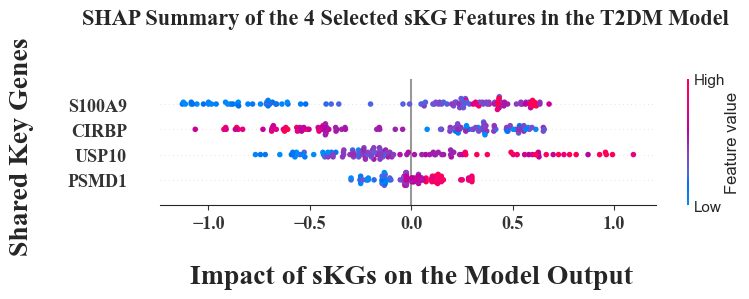

In [ ]:
selected_genes = ["S100A9","CIRBP","USP10","PSMD1"]

idx = [list(features_names_updates).index(g) for g in selected_genes]

shap_sub = shap_values[:, idx]
X_sub    = X_trans[:, idx]

import shap

# plt.figure(figsize=(6, 15))

shap.summary_plot(
    shap_sub,
    X_sub,
    feature_names=selected_genes,
    show=False,
)

plt.title("SHAP Summary of the 4 Selected sKG Features in the T2DM Model \n \n",
           fontsize=16, weight=800,fontfamily = "Times new roman")
plt.xlabel("\n Impact of sKGs on the Model Output",
           fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.ylabel("Shared Key Genes \n ",fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.xticks(fontsize = 13, fontweight = 800, fontfamily = "Times new roman")
plt.yticks(fontsize = 13, fontweight = "bold", fontfamily = "Times new roman")


plt.tight_layout()
# plt.show()


plt.savefig("/home/kaderi/Feroj/T2DM&TNBC/figures/ML_plot_important_gene/T2DM/SHAP_summary_plot_T2DM_Skgs_ALL.png", dpi=600, bbox_inches="tight")

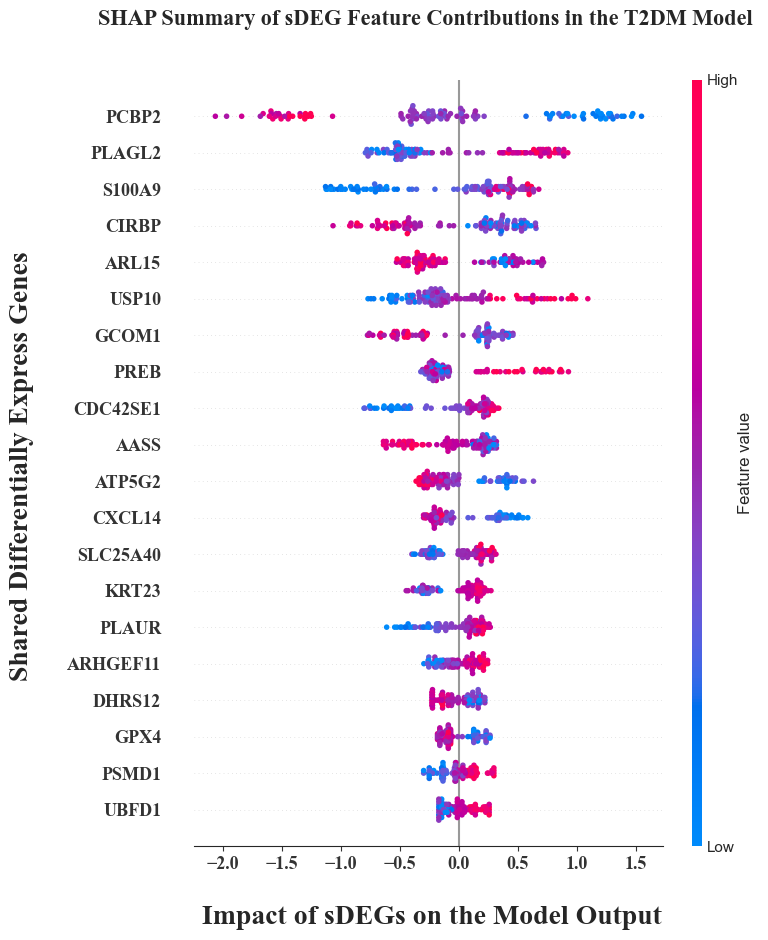

In [64]:

# plt.figure(figsize=(6, 15))

shap.summary_plot(
    shap_values,
    X_trans,
    feature_names=importance_df['feature'],
    show=False,
)

plt.title("SHAP Summary of sDEG Feature Contributions in the T2DM Model \n \n",
           fontsize=16, weight=800,fontfamily = "Times new roman")
plt.xlabel("\n Impact of sDEGs on the Model Output",
           fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.ylabel("Shared Differentially Express Genes \n ",fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.xticks(fontsize = 13, fontweight = 800, fontfamily = "Times new roman")
plt.yticks(fontsize = 13, fontweight = "bold", fontfamily = "Times new roman")


plt.tight_layout()
# plt.show()


plt.savefig("/home/kaderi/Feroj/T2DM&TNBC/figures/ML_plot_important_gene/T2DM/SHAP_summary_plot_T2DM_sDEGs.png", dpi=300, bbox_inches="tight")

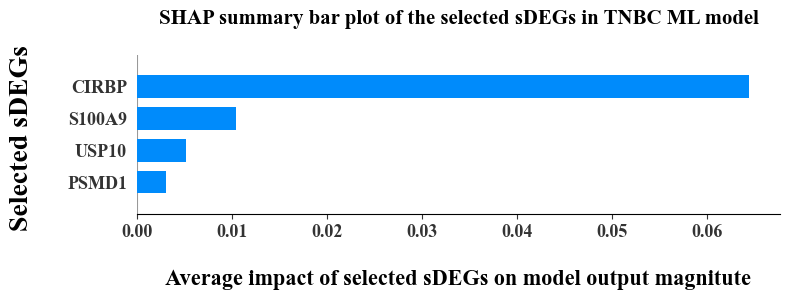

In [ ]:
selected_genes = ["S100A9","CIRBP","USP10","PSMD1"]

idx = [list(features_names_updates).index(g) for g in selected_genes]

shap_sub = shap_values[:, idx]
X_sub    = X_trans[:, idx]

import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(6, 15))

shap.summary_plot(
    shap_sub,
    X_sub,
    feature_names=selected_genes,
    show=False,
    plot_type = 'bar'
)

plt.title("SHAP summary bar plot of the selected sDEGs in TNBC ML model\n",
           fontsize=15, weight=800,fontfamily = "Times new roman")
plt.xlabel("\n Average impact of selected sDEGs on model output magnitute ",
           fontsize = 16, fontweight = 800,fontfamily = "Times new roman")
plt.ylabel("Selected sDEGs \n ",fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.xticks(fontsize = 13, fontweight = 800, fontfamily = "Times new roman")
plt.yticks(fontsize = 13, fontweight = "bold", fontfamily = "Times new roman")


plt.tight_layout()
# plt.show()


# plt.savefig("/home/kaderi/Feroj/T2DM&TNBC/figures/SHAP_bar_summary_plot_T2DM.png", dpi=300, bbox_inches="tight")

In [ ]:

sns.set_style("white") 
y_pred_proba = fitted_model.predict_proba(X1)[:, 1]
roc_auc = roc_auc_score(Y, y_pred_proba)
print("ROC–AUC Score:", roc_auc)
fpr, tpr, thresholds = roc_curve(Y, y_pred_proba)

plt.figure(figsize=(8, 4))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {round(roc_auc,4)})',color = 'green',linewidth = 3)
plt.plot([0, 1], [0, 1], 'k--',label='Random Chance',color = 'red', linewidth = 3)
plt.xlabel("\n False Positive Rate",fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.ylabel("True Positive Rate\n",fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.title("ROC Curve of T2DM Model\n ",fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
plt.legend(loc="lower right",fontsize = 14)
plt.grid(True,alpha=0.5)

plt.savefig("/home/kaderi/Feroj/T2DM&TNBC/figures/ML_plot_important_gene/T2DM/ROC_curve_of_T2DM.png", dpi=300, bbox_inches="tight")

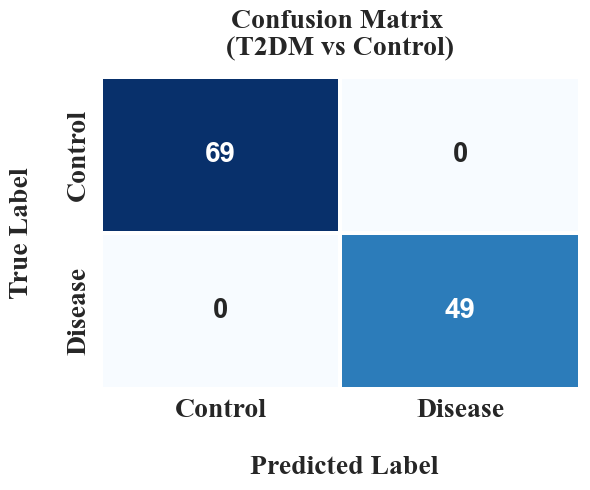

In [ ]:
from sklearn.metrics import confusion_matrix

y_pred = fitted_model.predict(X1)
cm = confusion_matrix(Y, y_pred)


plt.figure(figsize=(6, 5))

sns.set_style("white") 


ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1.5,
    linecolor="white",
    cbar=False, 
    annot_kws={"size": 20, "weight": "bold"}
)

ax.set_xlabel("\n Predicted Label", fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
ax.set_ylabel("True Label\n", fontsize = 20, fontweight = 800,fontfamily = "Times new roman")


ax.set_xticklabels(["Control", "Disease"], fontsize = 20, fontweight = 800,fontfamily = "Times new roman")
ax.set_yticklabels(["Control", "Disease"], fontsize = 20, fontweight = 800,fontfamily = "Times new roman")


plt.title("Confusion Matrix \n(T2DM vs Control)",fontsize = 20, fontweight = 800,fontfamily = "Times new roman", pad=15)
# plt.axvline(True)
# plt.axhline(True)
plt.tight_layout()
# plt.show()
plt.savefig("/home/kaderi/Feroj/T2DM&TNBC/figures/ML_plot_important_gene/T2DM/T2DM_Confusion_matrix.png", dpi=300, bbox_inches="tight")
